In [2]:
import soccerdata as sd
import matplotlib.pyplot as plt
import pandas as pd

In [3]:
fbref = sd.FBref(
    leagues = "ENG-Premier League",
    seasons = "2025-2026",
    path_to_browser = "/usr/bin/google-chrome",
    headless = True
)

[08/01/26 14:56:54] INFO     Saving cached data to C:\Users\malco\soccerdata\data\FBref              ]8;id=8243046;file://C:\Users\malco\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\LocalCache\local-packages\Python313\site-packages\soccerdata\_common.py\_common.py]8;;\:]8;id=8243047;file://C:\Users\malco\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\LocalCache\local-packages\Python313\site-packages\soccerdata\_common.py#250\250]8;;\


(Will use default settings...)



In [4]:
#this line of code gets player data for the 2025-2026 season in the English Premier League. The data is retrieved using the FBref class from the soccerdata library, which allows for easy access to football statistics. The read_player_season_stats method is called with the parameter stat_type set to "standard", which specifies that standard player statistics should be retrieved. The resulting data is stored in the variable pt.
pt = fbref.read_player_season_stats(stat_type = "standard")

In [21]:
#these lines of code sort the player data by index and display the first few rows of the sorted data. The sort_index method is called on the pt DataFrame to sort the data based on the index, which is typically a combination of player names and teams. The head method is then called to display the first few rows of the sorted DataFrame.
pt = pt.sort_index()
pt.head()

#this line of code retrieves player data specifically for the team "Manchester Utd" from the pt DataFrame. The xs method is called on the pt DataFrame with the parameter "Manchester Utd" and level set to "team". This allows for selecting data corresponding to the specified team from a multi-level index DataFrame, where "team" is one of the levels in the index. The resulting data for Manchester Utd players is returned.
man_utd_data = pt.xs("Manchester Utd", level = "team")

In [22]:
#resetting the dataframe index for the man_utd_data DataFrame. The reset_index method is called on the man_utd_data DataFrame to reset the index, which means that the current index will be replaced with a default integer index. This is often done to simplify the DataFrame structure and make it easier to work with, especially when performing further analysis or visualizations.
man_utd_data = man_utd_data.reset_index()

In [ ]:
#these lines of code define the column names for goals and assists in the man_utd_data DataFrame. The goals_col variable is assigned a tuple containing the column names for goals per 90 minutes and total goals, while the assists_col variable is assigned a tuple containing the column names for assists per 90 minutes and total assists. These tuples are used to access the corresponding columns in the DataFrame for further calculations.
goals_col = ('Per 90 Minutes', 'Gls')
assists_col = ('Per 90 Minutes', 'Ast')

#these lines of code calculate the impact score for each player in the man_utd_data DataFrame. The impact score is calculated using a weighted formula that takes into account the number of goals and assists scored by each player. The formula assigns a weight of 2.5 to goals and a weight of 2.0 to assists. The resulting impact scores are stored in a new column called "Impact Score" in the man_utd_data DataFrame.
man_utd_data["Impact Score"] = (
    2.5* man_utd_data[goals_col] + 
    2.0* man_utd_data[assists_col]
)

#these lines of code define the column names for impact score and playing time in the man_utd_data DataFrame. The impact_score_col variable is assigned a tuple containing the column names for impact score, while the playing_time_col variable is assigned a tuple containing the column names for playing time in minutes. These tuples are used to access the corresponding columns in the DataFrame for further calculations and filtering.
impact_score_col = ('Impact Score', '')
playing_time_col = ('Playing Time', 'Min')

#these lines of code filter the man_utd_data DataFrame to select the top 10 players based on their impact score, while also ensuring that they have played at least 1000 minutes. The filtering is done using a boolean condition that checks if the playing time is greater than or equal to 1000. The resulting filtered DataFrame is then sorted in descending order based on the impact score, and the top 10 players are selected using the head method. The final result is stored in the top_players variable.   
top_players = (
    man_utd_data[man_utd_data[playing_time_col] >= 1000]
    .sort_values(impact_score_col, ascending=False)
    .head(10)
)

player_col = ('player', '')

print(top_players[[player_col, playing_time_col, goals_col, assists_col, impact_score_col]])

             player Playing Time Per 90 Minutes       Impact Score
                             Min            Gls   Ast             
5   Bruno Fernandes         3063           0.26  0.62         1.89
4    Benjamin Šeško         1643            0.6  0.05          1.6
6      Bryan Mbeumo         2609           0.38   0.1         1.15
21    Patrick Dorgu         1449           0.25  0.25        1.125
18    Matheus Cunha         2494           0.36  0.07         1.04
7          Casemiro         2571           0.32  0.07         0.94
17      Mason Mount         1017           0.27   0.0        0.675
1       Amad Diallo         2341           0.08  0.12         0.44
9     Harry Maguire         1653           0.05  0.11        0.345
12    Kobbie Mainoo         1662           0.05  0.11        0.345


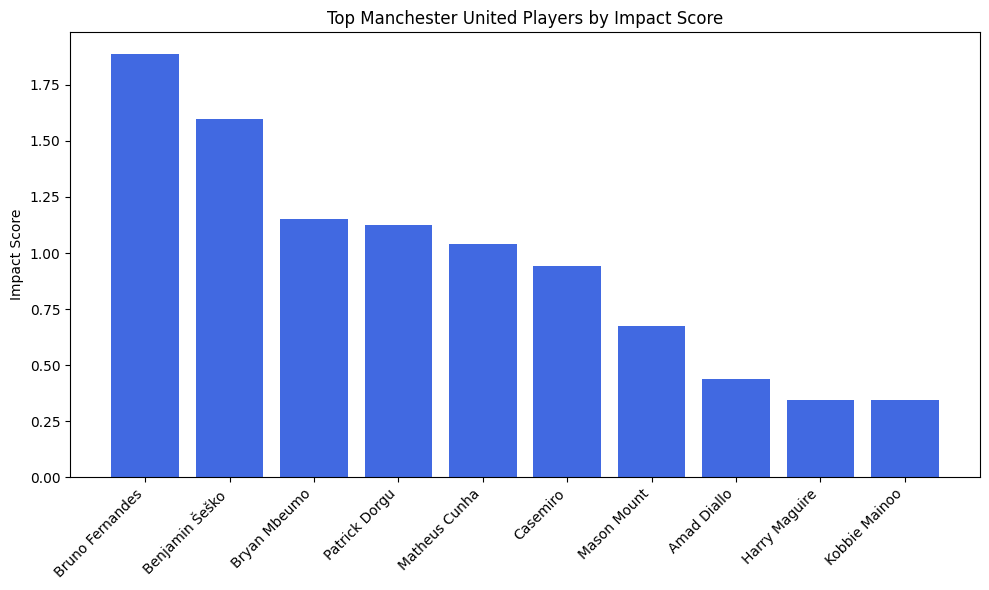

In [ ]:
#these lines of code create a bar chart to visualize the top Manchester United players based on their impact score. The plt.figure function is called to set the figure size, and the plt.bar function is used to create a bar chart with player names on the x-axis and their corresponding impact scores on the y-axis. The bars are colored in royal blue. The x-ticks are rotated for better readability, and labels for the y-axis and title are added. Finally, plt.tight_layout is called to adjust the layout, and plt.show is used to display the plot.
plt.figure(figsize=(10, 6))
plt.bar(top_players[player_col], top_players[impact_score_col], color="royalblue")
plt.xticks(rotation=45, ha="right")
plt.ylabel("Impact Score")
plt.title("Top Manchester United Players by Impact Score")
plt.tight_layout()
plt.show()
